# Dissecting Wan 2.2

The Wan22 notebook shows how to *use* the Wan 2.2 text-to-video model. This notebook takes
`Wan-AI/Wan2.2-TI2V-5B` apart with PyTorch introspection — printing modules, counting parameters, recording the
shapes of the tensors that flow through it — and rebuilds the generation loop by hand, to see how a sentence and
random noise become a video.

Wan 2.2 is a **latent diffusion** model for video, with four parts, all built from **convolutions, normalizations,
attention, dense layers and GELUs**:

- a **VAE** that compresses a video into a much smaller *latent* video and decodes it back;
- a **text encoder** (umT5-XXL) that turns the prompt into vectors;
- a **diffusion transformer** (DiT) that, given a noisy latent video, the text, and the noise level, predicts how to
  remove the noise;
- a **scheduler** that turns those predictions into a sequence of less and less noisy latents.

Like the Wan22 notebook, it needs a GPU instance (`ml.g4dn.4xlarge`) and caches the 34 GB of weights in `/tmp`.

In [1]:
import re
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
from diffusers import AutoencoderKLWan, WanPipeline
from diffusers.utils import logging as diffusers_logging
from huggingface_hub.utils import logging as hub_logging
from PIL import Image
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
diffusers_logging.set_verbosity_error()
diffusers_logging.disable_progress_bar()
hub_logging.set_verbosity_error()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*local_dir_use_symlinks.*")
%config InlineBackend.figure_formats = ['jpeg']
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'dpi': 144, 'pil_kwargs': {'quality': 85}}

device = "cuda"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

REPO, CACHE = "Wan-AI/Wan2.2-TI2V-5B-Diffusers", Path("/tmp/huggingface")
vae = AutoencoderKLWan.from_pretrained(REPO, subfolder="vae", dtype=torch.float32, cache_dir=CACHE)
pipe = WanPipeline.from_pretrained(REPO, vae=vae, dtype=torch.float16, cache_dir=CACHE)
pipe.enable_model_cpu_offload()   # each part moves to the GPU only while it runs
pipe.vae.enable_tiling()
pipe.set_progress_bar_config(disable=True)
transformer, text_encoder = pipe.transformer, pipe.text_encoder

## 1. The module tree

The transformer, printed (PyTorch collapses the 30 identical blocks: `(0-29): 30 x WanTransformerBlock`):

In [2]:
print(transformer)

WanTransformer3DModel(
  (rope): WanRotaryPosEmbed()
  (patch_embedding): Conv3d(48, 3072, kernel_size=(1, 2, 2), stride=(1, 2, 2))
  (condition_embedder): WanTimeTextImageEmbedding(
    (timesteps_proj): Timesteps()
    (time_embedder): TimestepEmbedding(
      (linear_1): Linear(in_features=256, out_features=3072, bias=True)
      (act): SiLU()
      (linear_2): Linear(in_features=3072, out_features=3072, bias=True)
    )
    (act_fn): SiLU()
    (time_proj): Linear(in_features=3072, out_features=18432, bias=True)
    (text_embedder): PixArtAlphaTextProjection(
      (linear_1): Linear(in_features=4096, out_features=3072, bias=True)
      (act_1): GELU(approximate='tanh')
      (linear_2): Linear(in_features=3072, out_features=3072, bias=True)
    )
  )
  (blocks): ModuleList(
    (0-29): 30 x WanTransformerBlock(
      (norm1): FP32LayerNorm((3072,), eps=1e-06, elementwise_affine=False, bias=False)
      (attn1): WanAttention(
        (to_q): Linear(in_features=3072, out_features=30

The configuration values that determine the architecture:

In [3]:
{
    "transformer": {k: transformer.config[k] for k in ["in_channels", "patch_size", "num_layers", "num_attention_heads",
                                                       "attention_head_dim", "ffn_dim", "text_dim", "freq_dim", "qk_norm"]},
    "vae": {k: vae.config[k] for k in ["z_dim", "patch_size", "scale_factor_temporal", "scale_factor_spatial"]},
    "text encoder": {"layers": text_encoder.config.num_layers, "width": text_encoder.config.d_model,
                     "max tokens": 512},
    "scheduler": {"class": type(pipe.scheduler).__name__, "prediction_type": pipe.scheduler.config.prediction_type,
                  "flow_shift": pipe.scheduler.config.flow_shift},
}

{'transformer': {'in_channels': 48,
  'patch_size': [1, 2, 2],
  'num_layers': 30,
  'num_attention_heads': 24,
  'attention_head_dim': 128,
  'ffn_dim': 14336,
  'text_dim': 4096,
  'freq_dim': 256,
  'qk_norm': 'rms_norm_across_heads'},
 'vae': {'z_dim': 48,
  'patch_size': 2,
  'scale_factor_temporal': 4,
  'scale_factor_spatial': 16},
 'text encoder': {'layers': 24, 'width': 4096, 'max tokens': 512},
 'scheduler': {'class': 'UniPCMultistepScheduler',
  'prediction_type': 'flow_prediction',
  'flow_shift': 5.0}}

### Where the parameters are

In [4]:
def n_params(module) -> int:
    return sum(p.numel() for p in module.parameters())


stages = {
    "text encoder (umT5-XXL)": [text_encoder],
    "VAE encoder": [vae.encoder, vae.quant_conv],
    "VAE decoder": [vae.decoder, vae.post_quant_conv],
    "transformer: patch_embedding": [transformer.patch_embedding],
    "transformer: condition_embedder (time, text)": [transformer.condition_embedder],
    "transformer: blocks (30x)": [transformer.blocks],
    "transformer: norm_out, proj_out": [transformer.norm_out, transformer.proj_out],
}
table = pd.DataFrame({"parameters": {name: sum(n_params(m) for m in ms) for name, ms in stages.items()}})
table.loc["total"] = table["parameters"].sum()
table["share"] = (table["parameters"] / table.loc["total", "parameters"]).map("{:.1%}".format)
table

,parameters,share
text encoder (umT5-XXL),5680910336,49.9%
VAE encoder,149637088,1.3%
VAE decoder,555051580,4.9%
transformer: patch_embedding,592896,0.0%
"transformer: condition_embedder (time, text)",88897536,0.8%
transformer: blocks (30x),4909701120,43.1%
"transformer: norm_out, proj_out",590016,0.0%
total,11385380572,100.0%


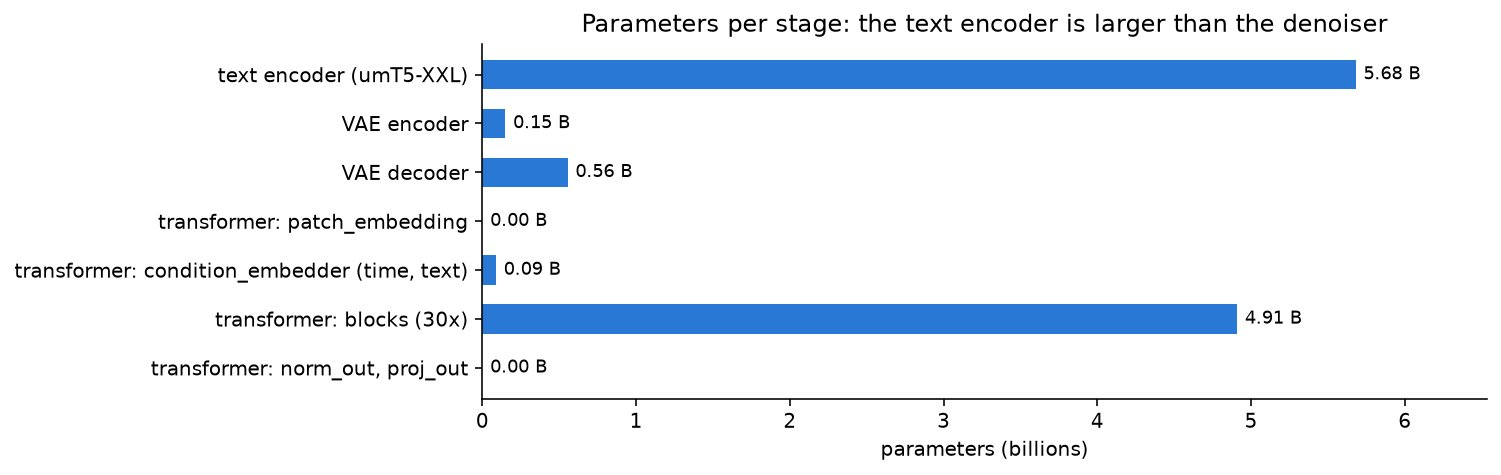

In [5]:
parts = table.drop(index="total")["parameters"][::-1] / 1e9
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(parts.index, parts.values, color=COLORS[0], height=0.6)
for y, v in enumerate(parts.values):
    ax.text(v + 0.05, y, f"{v:.2f} B", va="center", fontsize=9)
ax.set(xlabel="parameters (billions)", title="Parameters per stage: the text encoder is larger than the denoiser",
       xlim=(0, parts.max() * 1.15))
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [6]:
by_type = {}
for name, module in transformer.named_modules():
    own = sum(p.numel() for p in module.parameters(recurse=False))
    if own:
        count, total = by_type.get(type(module).__name__, (0, 0))
        by_type[type(module).__name__] = (count + 1, total + own)
pd.DataFrame(by_type, index=["modules", "parameters"]).T.sort_values("parameters", ascending=False)

,modules,parameters
Linear,306,4998082752
Conv3d,1,592896
WanTransformerBlock,30,552960
RMSNorm,120,368640
FP32LayerNorm,30,184320
WanTransformer3DModel,1,6144


In the transformer, almost everything is `Linear` layers. The 30 blocks each also own a `scale_shift_table`
(the `WanTransformerBlock` row): learned offsets for the time conditioning of section 5.

## 2. Tracing shapes with forward hooks

We run the transformer once on a random latent video of the size that a 2-second, 480 × 832 video has (section 3
explains the size), with a text embedding and one noise level, and record the shape of every basic block.

In [7]:
latent = torch.randn(1, 48, 13, 30, 52, dtype=torch.float16, device=device)          # (batch, channels, time, height, width)
text = torch.randn(1, 512, 4096, dtype=torch.float16, device=device)               # (batch, tokens, dimensions)
timestep = torch.full((1, 13 * 15 * 26), 500.0, device=device)                     # one noise level per video token

BASIC = (torch.nn.Conv3d, torch.nn.LayerNorm, torch.nn.Linear, torch.nn.SiLU, torch.nn.GELU)
records = []


def first_tensor(x):
    while isinstance(x, (tuple, list)):
        x = x[0]
    return x


def make_hook(name):
    def hook(module, args, kwargs, output):
        x = args[0] if args else next(iter(kwargs.values()))
        records.append({"module": name, "type": type(module).__name__, "input": tuple(first_tensor(x).shape),
                        "output": tuple(first_tensor(output).shape),
                        "parameters": 0 if "Attention" in type(module).__name__ else n_params(module)})
    return hook


handles = [m.register_forward_hook(make_hook(n), with_kwargs=True) for n, m in transformer.named_modules()
           if isinstance(m, BASIC) or type(m).__name__ in ("WanAttention", "RMSNorm", "FP32LayerNorm")]
with torch.no_grad():
    velocity = transformer(hidden_states=latent, timestep=timestep, encoder_hidden_states=text, return_dict=False)[0]
for h in handles:
    h.remove()

trace = pd.DataFrame(records)
trace["layer"] = trace["module"].str.extract(r"^blocks\.(\d+)\.")[0]
per_layer = [g[["type", "input", "output", "parameters"]].reset_index(drop=True) for _, g in trace.dropna(subset="layer").groupby("layer")]
assert len(per_layer) == 30 and all(p.equals(per_layer[0]) for p in per_layer)

collapsed = trace[trace["layer"].isna() | (trace["layer"] == "0")].drop(columns="layer").copy()
collapsed["module"] = collapsed["module"].str.replace(r"^blocks\.0\.", "blocks.*.", regex=True)
print("output (velocity):", tuple(velocity.shape), " — the same shape as the input latent")
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 60):
    display(collapsed.reset_index(drop=True))

output (velocity): (1, 48, 13, 30, 52)  — the same shape as the input latent


,module,type,input,output,parameters
0,patch_embedding,Conv3d,"(1, 48, 13, 30, 52)","(1, 3072, 13, 15, 26)",592896
1,condition_embedder.time_embedder.linear_1,Linear,"(1, 5070, 256)","(1, 5070, 3072)",789504
2,condition_embedder.time_embedder.act,SiLU,"(1, 5070, 3072)","(1, 5070, 3072)",0
3,condition_embedder.time_embedder.linear_2,Linear,"(1, 5070, 3072)","(1, 5070, 3072)",9440256
4,condition_embedder.act_fn,SiLU,"(1, 5070, 3072)","(1, 5070, 3072)",0
5,condition_embedder.time_proj,Linear,"(1, 5070, 3072)","(1, 5070, 18432)",56641536
6,condition_embedder.text_embedder.linear_1,Linear,"(1, 512, 4096)","(1, 512, 3072)",12585984
7,condition_embedder.text_embedder.act_1,GELU,"(1, 512, 3072)","(1, 512, 3072)",0
8,condition_embedder.text_embedder.linear_2,Linear,"(1, 512, 3072)","(1, 512, 3072)",9440256
9,blocks.*.norm1,FP32LayerNorm,"(1, 5070, 3072)","(1, 5070, 3072)",0


Reading the table:

- `patch_embedding`, a `Conv3d` with kernel = stride = (1, 2, 2), cuts the latent video into patches of 1 frame ×
  2 × 2 positions: 13 × 15 × 26 = **5070 tokens** of 3072 dimensions.
- The `condition_embedder` turns the noise level into a 3072-d vector (`time_embedder`) and then into **6 × 3072**
  numbers *per token* (`time_proj`, 18432 outputs): the shifts, scales and gates of section 5. Its `text_embedder`
  projects the 512 text vectors from 4096 to 3072 dimensions.
- In each block, `attn1` (self-attention) works on the 5070 video tokens; in `attn2` (cross-attention) the keys and
  values come from the 512 text tokens.
- `proj_out` maps each token to 192 = 48 channels × 2 × 2 positions, which are put back together into a latent video
  of the input's shape: the predicted **velocity** (section 6).

### The architecture as a diagram

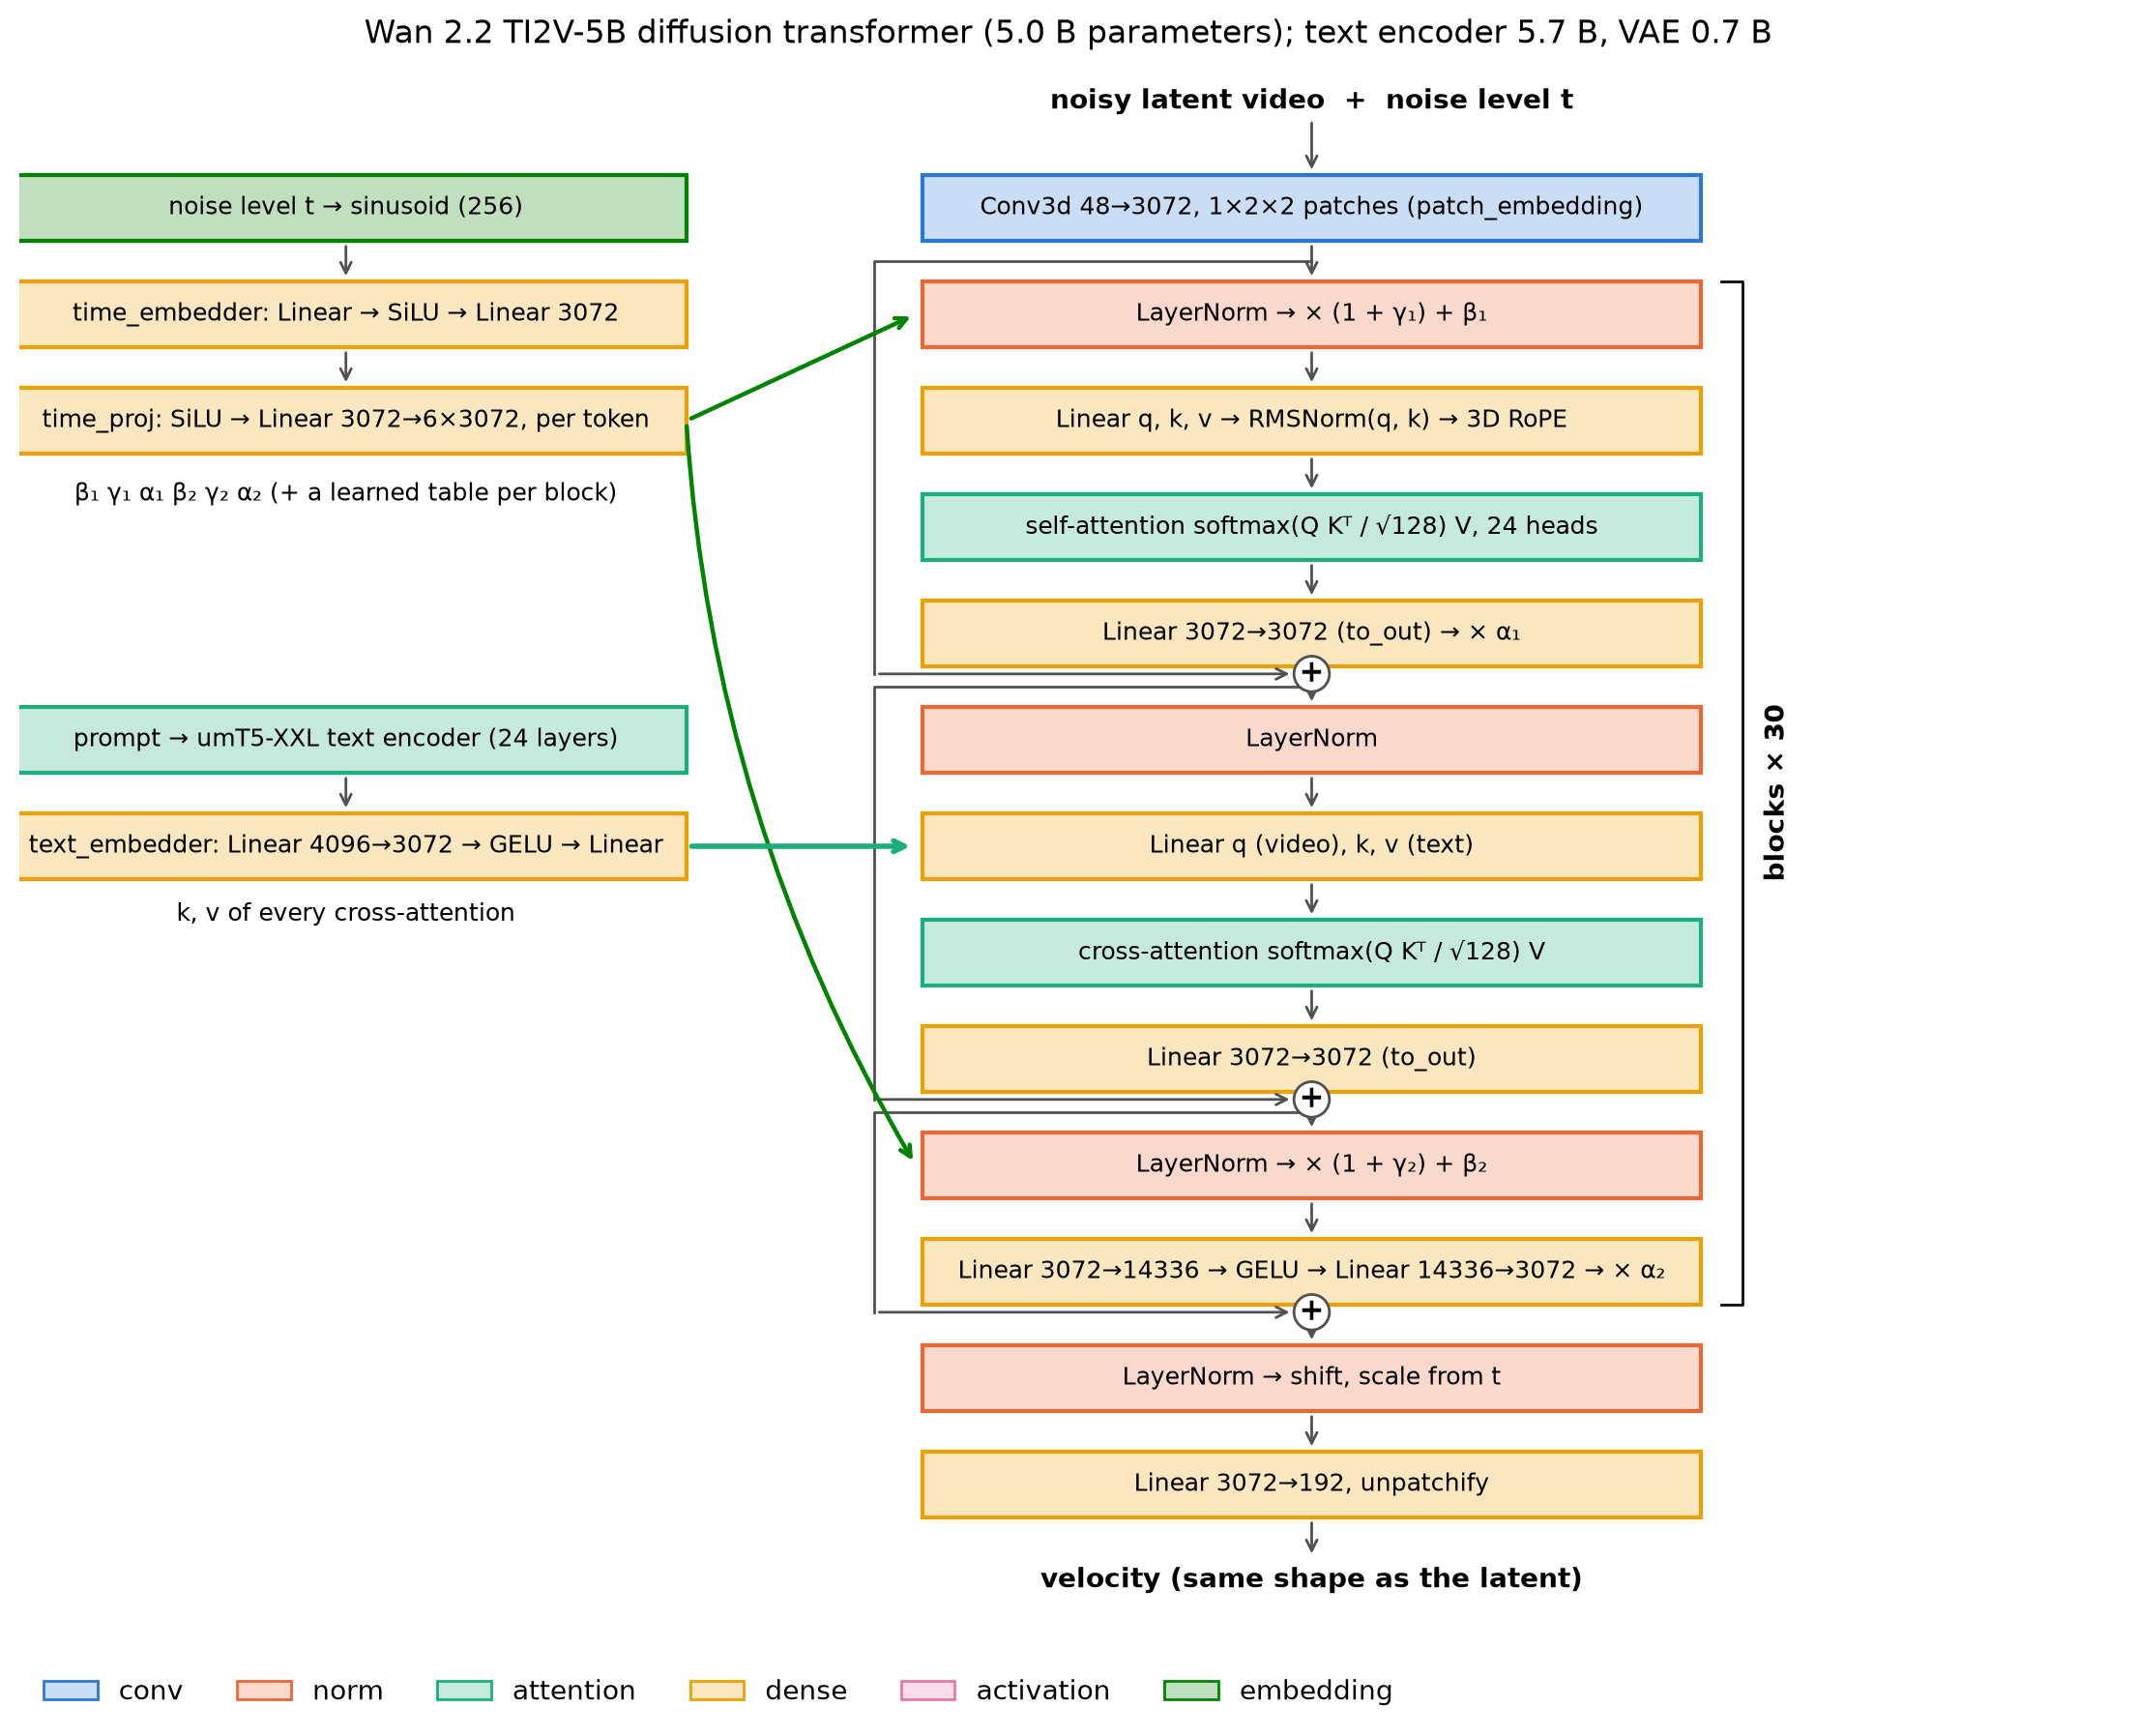

## 3. The VAE: a smaller video

Generating every pixel of every frame with a transformer would be far too expensive. Instead, the diffusion works in
the latent space of a **video VAE**: the encoder first rearranges each 2 × 2 block of pixels into channels, then
convolutions compress further — in total **16 × 16 in space and 4 × in time**, into 48 channels. The first frame is
encoded on its own (so that a single image is a valid 1-frame video), the others in groups of 4:

$$T_\text{latent} = 1 + \frac{T - 1}{4} \qquad H_\text{latent} = \frac{H}{16} \qquad W_\text{latent} = \frac{W}{16}$$

A 2-second video of 49 frames at 480 × 832 (58.7 M numbers) becomes 13 × 30 × 52 × 48 latent numbers (0.97 M):
**60 times fewer**. An image as a 1-frame video, through the encoder and the decoder:

image: (1, 3, 1, 480, 832) -> latent: (1, 48, 1, 30, 52) -> decoded: (1, 3, 1, 480, 832)
reconstruction PSNR: 26.9 dB


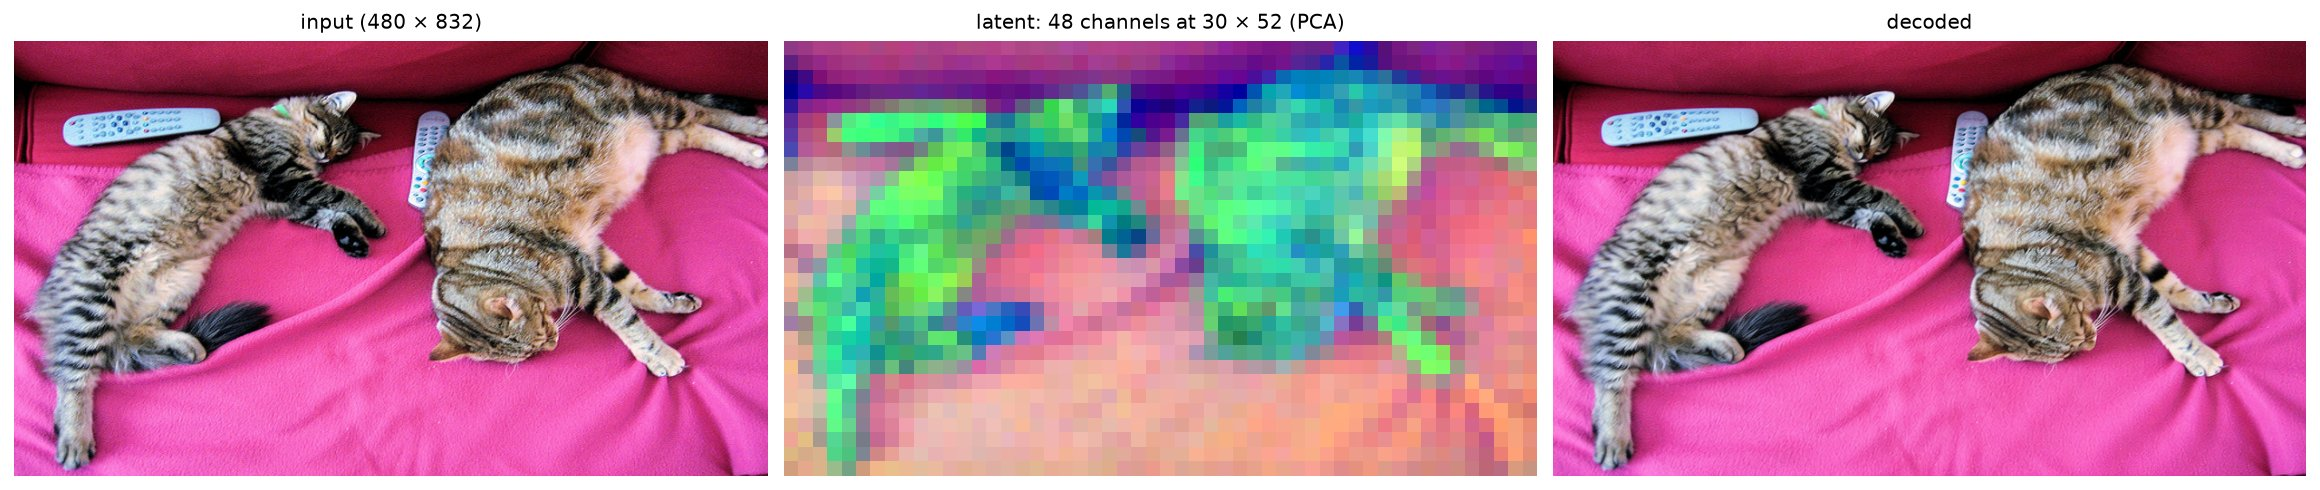

In [8]:
url = "https://s3.us-east-1.amazonaws.com/images.cocodataset.org/val2017/000000039769.jpg"
cats = Image.open(requests.get(url, stream=True).raw).convert("RGB").resize((832, 480))
pixels = torch.tensor(np.asarray(cats), dtype=torch.float32).permute(2, 0, 1)[None, :, None] / 127.5 - 1  # (1, 3, 1, 480, 832) in [-1, 1]

vae.to(device)
with torch.no_grad():
    encoded = vae.encode(pixels.to(device)).latent_dist.mode()                  # (1, 48, 1, 30, 52)
    decoded = vae.decode(encoded, return_dict=False)[0].clamp(-1, 1)
vae.to("cpu")
print("image:", tuple(pixels.shape), "-> latent:", tuple(encoded.shape), "-> decoded:", tuple(decoded.shape))
error = ((decoded.cpu() - pixels) ** 2).mean()
print(f"reconstruction PSNR: {10 * torch.log10(4 / error):.1f} dB")


def pca_rgb(features):
    c, h, w = features.shape
    x = features.reshape(c, -1).T.float()
    x = x - x.mean(dim=0)
    _, _, v = torch.pca_lowrank(x, q=3, center=False)
    rgb = (x @ v[:, :3]).reshape(h, w, 3)
    return ((rgb - rgb.quantile(0.01)) / (rgb.quantile(0.99) - rgb.quantile(0.01))).clamp(0, 1).cpu().numpy()


fig, axes = plt.subplots(1, 3, figsize=(16, 3.4), layout="constrained")
axes[0].imshow(cats)
axes[0].set_title("input (480 × 832)", fontsize=10)
axes[1].imshow(pca_rgb(encoded[0, :, 0]), interpolation="nearest")
axes[1].set_title("latent: 48 channels at 30 × 52 (PCA)", fontsize=10)
axes[2].imshow(((decoded[0, :, 0].cpu().permute(1, 2, 0) + 1) / 2).numpy())
axes[2].set_title("decoded", fontsize=10)
for ax in axes:
    ax.axis("off")
plt.show()

## 4. The text encoder

The prompt is split into tokens by a T5 tokenizer and encoded by **umT5-XXL** (a multilingual T5 encoder: 24
Transformer layers, 4096 dimensions). The pipeline always passes **512** vectors to the transformer: one per token,
and zeros after the end of the prompt. The zeros matter: the transformer gets no mask for them, so they take part in
the cross-attention — calling `encode_prompt` on its own pads to only 226 by default, which gives a different video
than `pipe(...)`.

In [9]:
prompt = "A cat walks on the grass, realistic, sunny day."
tokens = pipe.tokenizer(prompt).input_ids
print(len(tokens), "tokens:", pipe.tokenizer.convert_ids_to_tokens(tokens))
with torch.no_grad():
    embeds, negative_embeds = pipe.encode_prompt(prompt=prompt, negative_prompt="", device=device, max_sequence_length=512)
used = int((embeds[0].abs().sum(dim=-1) > 0).sum())
print("prompt embeddings:", tuple(embeds.shape), f"— {used} non-zero rows, {embeds.shape[1] - used} rows of zeros")

15 tokens: ['▁A', '▁cat', '▁walk', 's', '▁on', '▁the', '▁grass', ',', '▁realistic', ',', '▁sunn', 'y', '▁day', '.', '</s>']


prompt embeddings: (1, 512, 4096) — 15 non-zero rows, 497 rows of zeros


## 5. The diffusion transformer

**Positions.** Self-attention by itself doesn't know where a token is. Wan uses **3D rotary position embeddings**:
each 128-d attention head is split into a part rotated by the token's frame index, one by its row, and one by its
column (like the 3D RoPE of the V-JEPA 2 video encoder in module 5).

**Time conditioning (adaLN).** The noise level $t$ is not added as a token; it *modulates* every block. From $t$ the
`condition_embedder` computes six vectors — two shifts $\beta$, two scales $\gamma$, two gates $\alpha$ — added to a
learned per-block table, and each block does, with $x$ the video tokens and $c$ the text vectors:

$$h = x + \alpha_1 \odot \mathrm{SelfAttn}\big(\mathrm{LN}(x) \odot (1 + \gamma_1) + \beta_1\big)$$
$$g = h + \mathrm{CrossAttn}\big(\mathrm{LN}(h),\ c\big)$$
$$y = g + \alpha_2 \odot \mathrm{FFN}\big(\mathrm{LN}(g) \odot (1 + \gamma_2) + \beta_2\big)$$

(LN without its own scale and shift: those come from $t$.) The attention queries and keys are RMS-normalized
(`norm_q`, `norm_k`), which keeps attention stable in a large model.

In this "TI2V" model the noise level is given **per token** (the `timestep` of shape (batch, 5070) in section 2):
for image-to-video, the tokens of the first frame — the given image — get $t = 0$ (clean), all others the current
noise level. For text-to-video, all tokens get the same $t$.

## 6. Flow matching: from noise to video

Wan is trained with **flow matching** (rectified flow): a noisy latent at noise level $\sigma \in [0, 1]$ is a
straight-line mix of the clean latent $x_0$ and Gaussian noise $\epsilon$, and the transformer predicts the
**velocity** along that line:

$$x_\sigma = (1 - \sigma)\, x_0 + \sigma\, \epsilon \qquad\qquad v_\theta(x_\sigma, \sigma, c) \approx \epsilon - x_0$$

Generation starts at $\sigma = 1$ (pure noise) and walks to $\sigma = 0$; the scheduler (UniPC, a higher-order ODE
solver) decides the step sizes. With `flow_shift = 5`, the steps are spent mostly at high noise, where the layout and
motion of the video are decided:

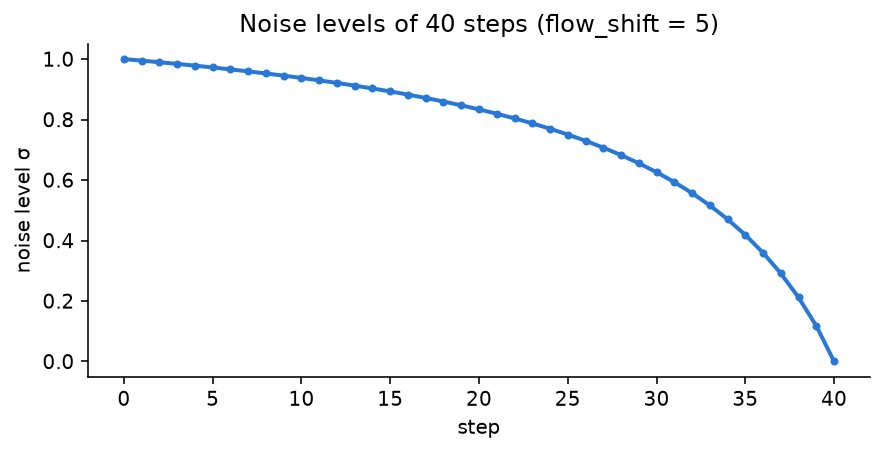

In [10]:
pipe.scheduler.set_timesteps(40, device=device)
sigmas = pipe.scheduler.sigmas.cpu().numpy()
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(len(sigmas)), sigmas, marker="o", color=COLORS[0], lw=2, ms=3)
ax.set(xlabel="step", ylabel="noise level σ", title="Noise levels of 40 steps (flow_shift = 5)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### The generation loop, by hand

Each step: run the transformer twice — with the prompt and with the negative prompt — and combine the two velocities
with **classifier-free guidance**, $v = v_\text{neg} + w\,(v_\text{prompt} - v_\text{neg})$; then let the scheduler
take the step. Along the way, $\hat{x}_0 = x_\sigma - \sigma v$ is the model's current guess of the final latent;
we keep it at a few steps to look at. At the end, the latent is un-normalized (the VAE's per-channel mean and std)
and decoded. We check that the loop gives the same latent as the pipeline.

In [11]:
NEGATIVE = "blurry, low quality, distorted, static, still picture, worst quality, watermark, text, subtitles"
STEPS, GUIDANCE, FRAMES, HEIGHT, WIDTH, SEED = 40, 5.0, 49, 480, 832, 0
with torch.no_grad():
    embeds, negative_embeds = pipe.encode_prompt(prompt=prompt, negative_prompt=NEGATIVE, device=device,
                                                 max_sequence_length=512)   # as pipe(...) does
embeds, negative_embeds = embeds.half(), negative_embeds.half()

pipe.scheduler.set_timesteps(STEPS, device=device)
pipe.scheduler.set_begin_index(0)
shape = (1, 48, 1 + (FRAMES - 1) // 4, HEIGHT // 16, WIDTH // 16)
latents = torch.randn(shape, generator=torch.Generator("cpu").manual_seed(SEED), dtype=torch.float32).to(device)
keep_at, guesses = {1, 5, 10, 20, 40}, {}

start = time.time()
with torch.no_grad():
    for step, t in enumerate(pipe.scheduler.timesteps, start=1):
        timestep = t.float().expand(1, shape[2] * (shape[3] // 2) * (shape[4] // 2))  # the same t for every token
        x = latents.half()
        v_prompt = transformer(hidden_states=x, timestep=timestep, encoder_hidden_states=embeds, return_dict=False)[0]
        v_negative = transformer(hidden_states=x, timestep=timestep, encoder_hidden_states=negative_embeds, return_dict=False)[0]
        v = v_negative + GUIDANCE * (v_prompt - v_negative)
        if step in keep_at:
            guesses[step] = (latents - pipe.scheduler.sigmas[step - 1] * v.float()).cpu()
        latents = pipe.scheduler.step(v, t, latents, return_dict=False)[0]
print(f"{STEPS} steps × 2 transformer passes in {time.time() - start:.0f} s; latent {tuple(latents.shape)}")

pipe.maybe_free_model_hooks()  # the loop above left the transformer on the GPU; move everything back to the CPU
reference = pipe(prompt=prompt, negative_prompt=NEGATIVE, height=HEIGHT, width=WIDTH, num_frames=FRAMES,
                 num_inference_steps=STEPS, guidance_scale=GUIDANCE, output_type="latent",
                 generator=torch.Generator("cpu").manual_seed(SEED)).frames
print("same latent as the pipeline:", torch.allclose(latents, reference.to(latents), atol=1e-2),
      f"(max difference {(latents - reference.to(latents)).abs().max():.4f})")

40 steps × 2 transformer passes in 47 s; latent (1, 48, 13, 30, 52)


same latent as the pipeline: True (max difference 0.0000)


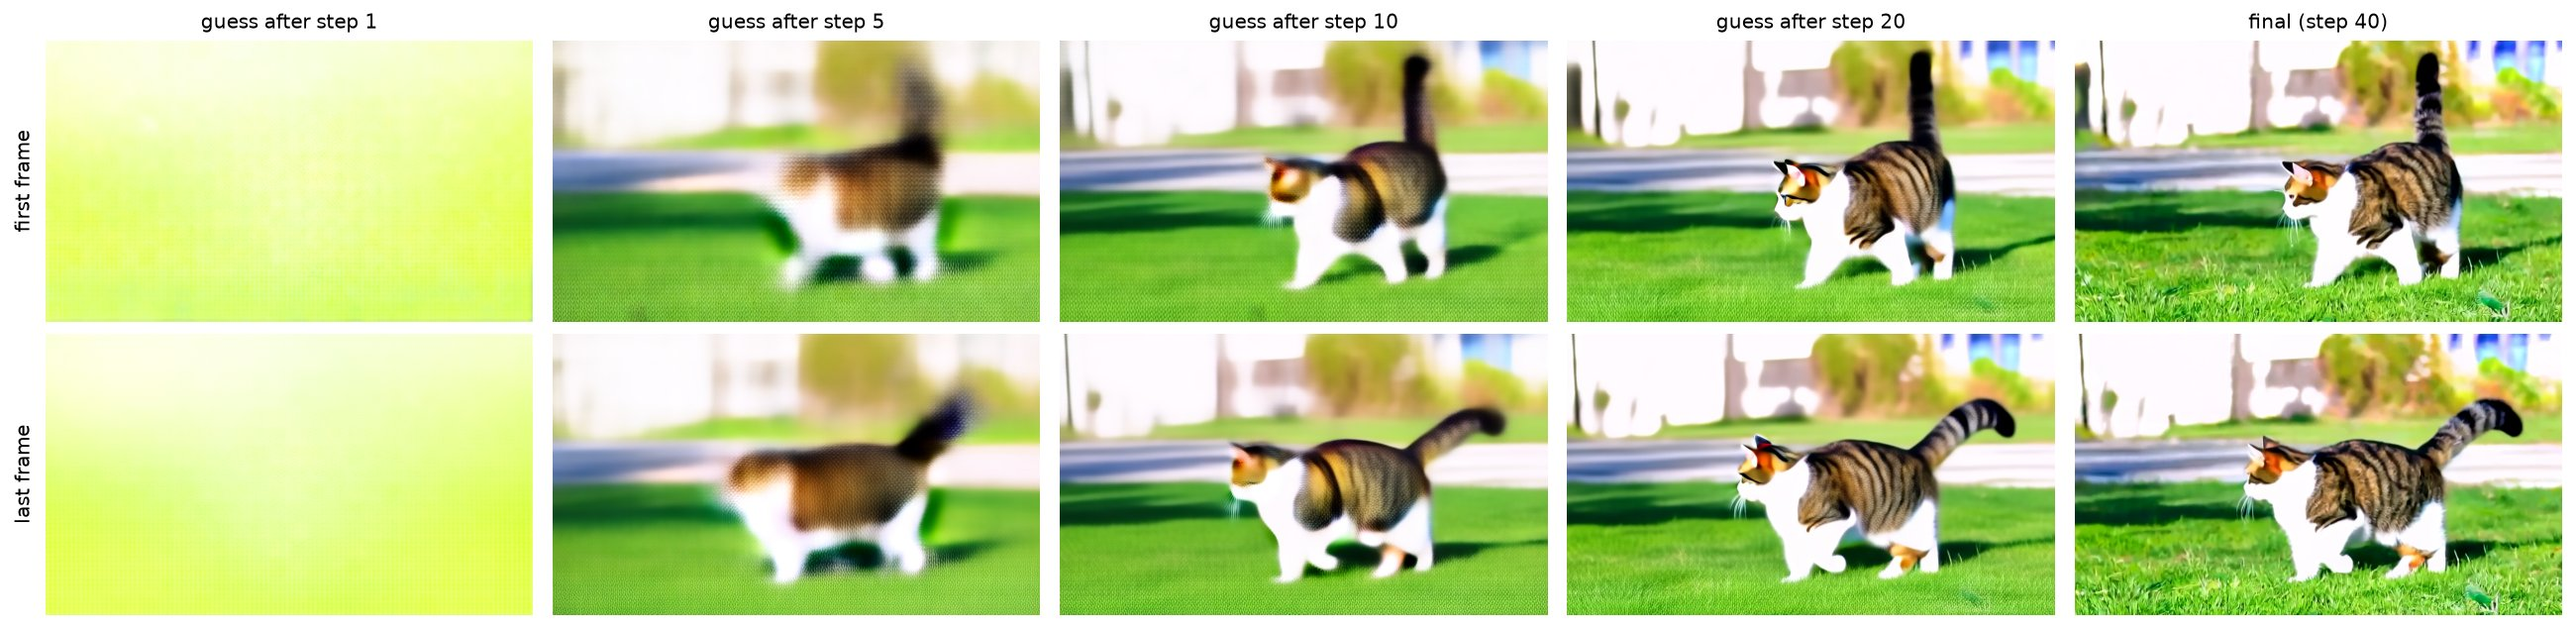

In [12]:
def decode(latent):
    """Un-normalizes a latent video and decodes it: (1, 48, T, h, w) -> (frames, height, width, 3) in [0, 1]."""
    mean = torch.tensor(vae.config.latents_mean).view(1, -1, 1, 1, 1)
    std = torch.tensor(vae.config.latents_std).view(1, -1, 1, 1, 1)
    vae.to(device)
    with torch.no_grad():
        video = vae.decode((latent.cpu().float() * std + mean).to(device), return_dict=False)[0]
    vae.to("cpu")
    return ((video[0].permute(1, 2, 3, 0).float().cpu().clamp(-1, 1) + 1) / 2).numpy()


guesses[STEPS] = latents.cpu()
fig, axes = plt.subplots(2, len(guesses), figsize=(18, 4.3), layout="constrained")
for column, (step, guess) in enumerate(sorted(guesses.items())):
    video = decode(guess)
    for row, frame in enumerate([0, len(video) - 1]):
        axes[row, column].imshow(video[frame])
        axes[row, column].axis("off")
    axes[0, column].set_title(f"guess after step {step}" if step < STEPS else f"final (step {STEPS})", fontsize=10)
axes[0, 0].text(-20, 240, "first frame", rotation=90, va="center", ha="right", fontsize=10)
axes[1, 0].text(-20, 240, "last frame", rotation=90, va="center", ha="right", fontsize=10)
plt.show()

After one step the guess is a blur with the right colors; by step 5–10 the layout and the motion (compare first
and last frame) are decided; the remaining steps add detail. This is why `flow_shift` spends most steps at high noise.

## Summary

- **VAE**: video → latent video, 4× smaller in time and 16 × 16 in space, 48 channels (60× fewer numbers);
- **Text encoder**: umT5-XXL, 512 vectors of 4096 (zeros after the prompt);
- **Transformer**: `Conv3d` patches (1 × 2 × 2) → 5070 tokens → 30 blocks of self-attention (3D RoPE), cross-attention
  to the text, and a feed-forward layer, all modulated by the noise level (adaLN, per token) → velocity;
- **Sampling**: flow matching from noise to video in 40 steps, with classifier-free guidance — two transformer passes
  per step.